# analisis de sentimiento de resenas de cine con regresion logistica
inf672 machine learning - segundo parcial

(limpieza, stopwords, stemming, vectorizacion y regresion logistica) pero ahora para saber si una resena de pelicula es positiva o negativa. el dataset es imdb dataset of 50k movie reviews de kaggle.

In [10]:
import re #exp regulares REGEX
import nltk #leamtizacion, stemming, stopwords, tokenizacion
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression 
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

#nltk.download('stopwords', quiet=True)

## 1. carga y exploracion

In [11]:
df = pd.read_csv('./parciales/IMDB Dataset.csv')
print(df.shape)
df.head()

(50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [12]:
# distribucion de clases, nulos y duplicados
print(df['sentiment'].value_counts())
print()
print('nulos:')
print(df.isnull().sum())
print()
print('duplicados:', df.duplicated().sum())

sentiment
positive    25000
negative    25000
Name: count, dtype: int64

nulos:
review       0
sentiment    0
dtype: int64

duplicados: 418


In [13]:
# elimino los duplicados
df = df.drop_duplicates().reset_index(drop=True)
print(df.shape)
print(df['sentiment'].value_counts())

(49582, 2)
sentiment
positive    24884
negative    24698
Name: count, dtype: int64


las clases estan casi balanceadas y no hay valores nulos. si hay resenas duplicadas y decidi eliminarlas, porque si una misma resena queda en entrenamiento y en prueba el modelo la veria dos veces y la exactitud saldria mas alta de lo real. al quitar duplicados las clases siguen casi iguales, asi que la exactitud sigue siendo una buena metrica.

In [14]:
# longitud de las resenas en palabras
df['n_palabras'] = df['review'].str.split().str.len()
print(df.groupby('sentiment')['n_palabras'].describe())

             count        mean         std   min    25%    50%    75%     max
sentiment                                                                    
negative   24698.0  229.596607  165.103430   4.0  128.0  174.0  278.0  1522.0
positive   24884.0  233.090620  177.688169  10.0  125.0  172.0  284.0  2470.0


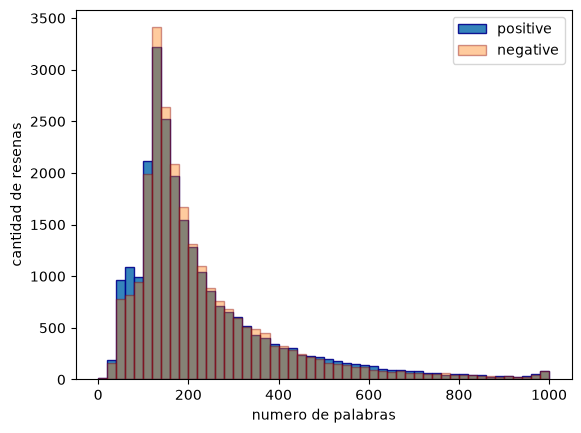

In [15]:
pos = df[df['sentiment'] == 'positive']['n_palabras']
neg = df[df['sentiment'] == 'negative']['n_palabras']

plt.hist(pos, bins=50, range=(0, 1000), alpha=0.9, label='positive', edgecolor='darkblue')
plt.hist(neg, bins=50, range=(0, 1000), alpha=0.4, label='negative', edgecolor='darkred')
plt.xlabel('numero de palabras')
plt.ylabel('cantidad de resenas')
plt.legend()
plt.show()

las dos distribuciones son muy parecidas: la mayoria de resenas es corta y hay pocas muy largas (cola hacia la derecha). las medias de ambas clases son cercanas, asi que la longitud no sirve para distinguir si una resena es positiva o negativa. hay que fijarse en las palabras que usan.

## 2. preprocesamiento del texto

In [16]:
# reviso algunas resenas para ver que cosas sucias tienen
for t in df['review'].sample(3, random_state=1):
    print(t[:400])
    print('-'*400)

I saw this show about 3-4 years ago. It was dam Funny! When i first time i saw it was playing on ETV(Estonian Television) And i started to like it. Too bad that that show is on bad time for me. Hyde is like a cool guy who likes to sing Frank Sinatra! And he comes on stupid ideas. He got these glasses which h are brown. I like it . And there's FeZ. The group Pervert. We all know what he does when h
----------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------------
Of the spate of Austen films from the 1990s, this is my favorite, more even than "Persuasion," which was the one that converted me to Austeniana. Before seeing this "Emma" I had seen two previous ve

In [17]:
# cuantas resenas tienen cada elemento
print('con etiquetas html:', df['review'].str.contains('<.*?>').mean())
print('con urls          :', df['review'].str.contains('http').mean())
print('con numeros       :', df['review'].str.contains(r'\d').mean())
print('con mayusculas    :', df['review'].str.contains('[A-Z]').mean())
print('con apostrofes    :', df['review'].str.contains("'").mean())

con etiquetas html: 0.5842442821991852
con urls          : 0.002420233149126699
con numeros       : 0.5604049856802872
con mayusculas    : 0.9956032431124199
con apostrofes    : 0.8891331531604211


las resenas tienen etiquetas html, mayusculas, numeros, signos de puntuacion y apostrofes. las urls casi no aparecen, asi que no hago una funcion para quitar urls (solo limpio lo que si existe).

sobre las stopwords: la lista de nltk incluye palabras como `not`, `no`, `nor`, `but`, `don't`. en sentimiento eso es un problema, porque "not good" y "good" quedarian iguales despues de quitar el `not`, y el significado se invierte. por eso decidi **conservar las negaciones** y quitar solo las demas stopwords. tambien cambio `n't` por `not` antes de quitar la puntuacion, porque si no `don't` queda como `don t` y se pierde la negacion.

In [18]:
stemmer = PorterStemmer()
stop_nltk = set(stopwords.words('english'))

# negaciones que CONSERVAMOS
negaciones = {'not', 'no', 'nor', 'but', 'against', 'very', 'too', 'few', 'don', 'doesn', 'didn', 'isn', 'wasn',
              'aren', 'weren', 'hasn', 'haven', 'hadn', 'couldn', 'shouldn', 'wouldn', 'won', 'mightn',
              'mustn', 'needn', 'shan', 'ain'}
stop_mias = stop_nltk - negaciones

def preprocesar(texto, stop=stop_mias):
    texto = texto.lower()
    texto = re.sub(r'<.*?>', ' ', texto)           # quita html
    texto = texto.replace("won't", "will not")
    texto = texto.replace("can't", "can not")
    texto = re.sub(r"n't\b", " not", texto)         # don't -> do not
    texto = re.sub(r'[^a-z\s]', ' ', texto)         # quita puntuacion y numeros
    palabras = [p for p in texto.split() if p not in stop]
    palabras = [stemmer.stem(p) for p in palabras]
    return ' '.join(palabras)

ejemplo = "This movie wasn't good, <br />but I didn't hate it at all!"
print('input -> ', ejemplo)
print('output -> ',preprocesar(ejemplo))

input ->  This movie wasn't good, <br />but I didn't hate it at all!
output ->  movi not good but not hate


In [19]:
N = 5000
if N:
    dfm = pd.concat([df[df['sentiment'] == 'positive'].sample(N // 2, random_state=42),
                     df[df['sentiment'] == 'negative'].sample(N // 2, random_state=42)])
    dfm = dfm.reset_index(drop=True)
else:
    dfm = df.copy()

dfm['y'] = (dfm['sentiment'] == 'positive').astype(int)
dfm['limpio'] = dfm['review'].apply(preprocesar)
print(dfm['sentiment'].value_counts())
dfm[['review', 'limpio']].head(3)

sentiment
positive    2500
negative    2500
Name: count, dtype: int64


,review,limpio
0,Not since The Simpsons made it's debut has the...,not sinc simpson made debut sitcom not want tu...
1,It's a strange thing to see a film where some ...,strang thing see film scene work rather weakli...
2,"Real cool, smart movie. I loved Sheedy's color...",real cool smart movi love sheedi color especi ...


In [20]:
# experimento: stopwords de nltk completas vs conservando negaciones
dfm['limpio_nltk'] = dfm['review'].apply(lambda t: preprocesar(t, stop_nltk))

for col in ['limpio_nltk', 'limpio']:
    Xtr, Xte, ytr, yte = train_test_split(dfm[col], dfm['y'], test_size=0.2, stratify=dfm['y'], random_state=42)
    vec = CountVectorizer()
    mod = LogisticRegression(max_iter=1000)
    mod.fit(vec.fit_transform(Xtr), ytr)
    print(col, '-> exactitud:', round(accuracy_score(yte, mod.predict(vec.transform(Xte))), 4))

limpio_nltk -> exactitud: 0.843
limpio -> exactitud: 0.836


arriba se ve que nltk y conservando las negaciones la diferencia es de solo 0.007 puntos (unas 7 resenias de 1000), asi que es practicamente un empate y puede deberse al azar de la muestra de 5000.

conservar el `not` es lo correcto linguisticamente, porque "not good" y "good" no pueden quedar iguales en un problema de sentimiento.

## 3. division de los datos

In [21]:
train, test = train_test_split(dfm, test_size=0.2, stratify=dfm['y'], random_state=42)

X_train, y_train = train['limpio'], train['y']
X_test, y_test = test['limpio'], test['y']

print('entrenamiento:', X_train.shape[0], '- proporcion positivas:', round(y_train.mean(), 3))
print('prueba:', X_test.shape[0], '- proporcion positivas:', round(y_test.mean(), 3))

entrenamiento: 4000 - proporcion positivas: 0.5
prueba: 1000 - proporcion positivas: 0.5


`stratify` para mantener la misma proporcion de clases y `random_state=42` para que el resultado se pueda repetir.

**por que el vectorizador se ajusta (fit) solo con entrenamiento:** el vectorizador aprende el vocabulario (y en tf-idf tambien cuantos documentos tienen cada palabra). si hiciera el fit con todos los datos, el modelo ya habria visto informacion del conjunto de prueba (data leakage) y la evaluacion saldria mas optimista de lo real. en prueba solo uso `transform`, y las palabras que no estaban en entrenamiento se ignoran, igual que pasaria con resenas nuevas en la vida real.

## 4. vectorizacion

**modelo a, bag of words (countvectorizer):** cada resena se convierte en un vector que cuenta cuantas veces aparece cada palabra del vocabulario. no importa el orden de las palabras.

**modelo b, tf-idf:** tambien cuenta palabras pero les da un peso. tf (term frequency) es que tanto aparece una palabra en esa resena, e idf (inverse document frequency) baja el peso de las palabras que aparecen en casi todas las resenas (como "movi" o "film") y sube el de las palabras raras que si distinguen. entonces las palabras que aparecen en todos lados valen poco y las palabras mas especificas valen mas. ademas los vectores se normalizan, asi que el largo de la resena influye menos.

In [22]:
# experimento con parametros (max_features, min_df y ngram_range)
configs = [('bow', CountVectorizer, {}),
           ('bow', CountVectorizer, {'max_features': 5000}),
           ('bow', CountVectorizer, {'min_df': 2}),
           ('bow', CountVectorizer, {'ngram_range': (1, 2), 'min_df': 2}),
           ('tfidf', TfidfVectorizer, {}),
           ('tfidf', TfidfVectorizer, {'max_features': 5000}),
           ('tfidf', TfidfVectorizer, {'min_df': 2}),
           ('tfidf', TfidfVectorizer, {'ngram_range': (1, 2), 'min_df': 2})]

filas = []
for nombre, Vec, params in configs:
    vec = Vec(**params)
    Xtr = vec.fit_transform(X_train)
    Xte = vec.transform(X_test)
    mod = LogisticRegression(max_iter=1000)
    mod.fit(Xtr, y_train)
    filas.append([nombre, str(params), Xtr.shape[1], round(accuracy_score(y_test, mod.predict(Xte)), 4)])

pd.DataFrame(filas, columns=['vectorizador', 'parametros', 'n_variables', 'exactitud'])

,vectorizador,parametros,n_variables,exactitud
0,bow,{},23512,0.836
1,bow,{'max_features': 5000},5000,0.831
2,bow,{'min_df': 2},13099,0.833
3,bow,"{'ngram_range': (1, 2), 'min_df': 2}",60759,0.856
4,tfidf,{},23512,0.861
5,tfidf,{'max_features': 5000},5000,0.863
6,tfidf,{'min_df': 2},13099,0.863
7,tfidf,"{'ngram_range': (1, 2), 'min_df': 2}",60759,0.865


en la tabla se ve como cambian la exactitud y el numero de variables segun el parametro:
- `max_features=5000` reduce el vocabulario de 23512 a 5000 palabras y la exactitud casi no cambia (bow 0.836 -> 0.831, tf-idf 0.861 -> 0.863). el modelo queda mucho mas liviano casi sin perder nada.
- `min_df=2` quita las palabras que aparecen en una sola resena (casi siempre errores de escritura o nombres raros) y baja el vocabulario a 13099. la exactitud tampoco cambia mucho (bow 0.833, tf-idf 0.863).
- `ngram_range=(1, 2)` agrega pares de palabras como "not good" o "waste of" y sube las variables a 60759. en bow es la mejora mas grande (0.836 -> 0.856, unos 2 puntos). en tf-idf la mejora es chica (0.861 -> 0.865).
- tf-idf frente a bow: tf-idf salio mejor en todas las configuraciones comparables (0.861 contra 0.836 sin parametros, 0.863 contra 0.831 con 5000 variables, 0.863 contra 0.833 con min_df=2). la diferencia se achica con bigramas (0.865 contra 0.856). creo que pasa porque tf-idf baja el peso de las palabras que aparecen en casi todas las resenas y normaliza el largo de cada vector, mientras que bow usa conteos crudos, que en resenas largas toman valores grandes y le dificultan el trabajo a la regresion logistica.

como la muestra de prueba tiene solo 1000 resenas, una diferencia de 0.5 puntos son unas 5 resenas y puede ser azar. por eso las mejoras chicas (como 0.863 a 0.865) no se pueden considerar reales, pero las de 2 o 3 puntos (bigramas en bow, tf-idf contra bow) si son consistentes.

## 5. entrenamiento y evaluacion

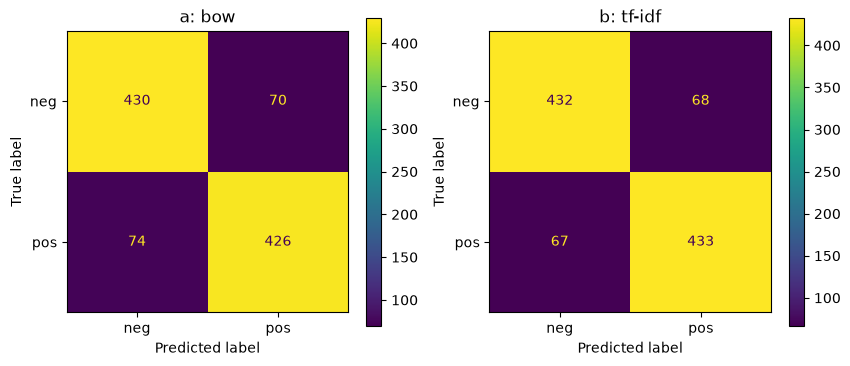

,accuracy,precision,recall,f1
modelo,,,,
a: bow,0.856,0.8589,0.852,0.8554
b: tf-idf,0.865,0.8643,0.866,0.8651


In [23]:
# para que la comparacion sea justa uso los mismos parametros en ambos, solo cambia el vectorizador
vec_a = CountVectorizer(ngram_range=(1, 2), min_df=2)
vec_b = TfidfVectorizer(ngram_range=(1, 2), min_df=2)

resultados = []
modelos = {}

fig, ejes = plt.subplots(1, 2, figsize=(10, 4))
for eje, nombre, vec in zip(ejes, ['a: bow', 'b: tf-idf'], [vec_a, vec_b]):
    Xtr = vec.fit_transform(X_train)
    Xte = vec.transform(X_test)
    mod = LogisticRegression(max_iter=1000)
    mod.fit(Xtr, y_train)
    pred = mod.predict(Xte)
    modelos[nombre] = (vec, mod)

    resultados.append([nombre, accuracy_score(y_test, pred), precision_score(y_test, pred),
                       recall_score(y_test, pred), f1_score(y_test, pred)])
    ConfusionMatrixDisplay(confusion_matrix(y_test, pred), display_labels=['neg', 'pos']).plot(ax=eje)
    eje.set_title(nombre)
plt.show()

tabla = pd.DataFrame(resultados, columns=['modelo', 'accuracy', 'precision', 'recall', 'f1']).set_index('modelo')
tabla.round(4)

elegimos el modelo que tenga el f1 mas alto (el codigo de la siguiente seccion lo selecciona solo con `idxmax`). como las clases estan balanceadas, la exactitud y el f1 dan casi lo mismo. si la diferencia entre los dos modelos es muy pequena, cualquiera sirve, pero me quedo con el mejor numero y ademas reviso que los falsos positivos y los falsos negativos esten parecidos en la matriz, es decir que el modelo no favorezca a una sola clase.

## 6. interpretacion del modelo

In [24]:
# palabras con coeficientes mas positivos y mas negativos del mejor modelo
mejor = tabla['f1'].idxmax()
print('mejor modelo:', mejor)
vec, mod = modelos[mejor]

palabras = np.array(vec.get_feature_names_out())
coef = mod.coef_[0]
orden = np.argsort(coef)

print()
print('15 mas positivas:')
for i in orden[::-1][:15]:
    print(' ', palabras[i], round(coef[i], 2))

print()
print('15 mas negativas:')
for i in orden[:15]:
    print(' ', palabras[i], round(coef[i], 2))

mejor modelo: b: tf-idf

15 mas positivas:
  great 3.94
  love 3.57
  excel 2.81
  best 2.8
  enjoy 2.47
  well 2.21
  perform 2.04
  life 1.99
  beauti 1.88
  veri 1.82
  definit 1.81
  perfect 1.73
  amaz 1.71
  favorit 1.7
  also 1.65

15 mas negativas:
  bad -5.0
  worst -3.38
  no -2.8
  aw -2.65
  wast -2.6
  noth -2.56
  bore -2.46
  not -2.42
  stupid -2.33
  terribl -2.3
  poor -2.26
  even -2.06
  not even -2.01
  could -2.0
  wors -1.98


las palabras con coeficiente positivo empujan la prediccion hacia positivo y las negativas hacia negativo. en general tienen sentido. Se ven recortadas porque el stemming deja solo la raiz (por ejemplo "excel" viene de excellent y "terribl" de terrible).

algo importante es que `no` (-2.8), `not` (-2.42) y el bigrama `not even` (-2.01) quedaron entre las palabras mas negativas. esto confirma que conservar las negaciones fue util: si hubiera usado la lista completa de nltk estas palabras no estarian y el modelo perderia esa informacion.

tambien hay palabras que no son opinion pura: `life`, `also`, `veri`, `perform`, `well`, `definit` (positivas) y `even`, `could` (negativas). creo que aparecen porque se repiten mas en cierto tipo de resena: por ejemplo "could" aparece en frases como "could have been better", y "life" en resenas que elogian peliculas sobre temas profundos. son coeficientes mas bajos que los de las palabras de opinion, asi que pesan menos en la decision.

In [25]:
# 3 resenas propias: positiva, negativa y sarcastica
propias = ["An absolutely brilliant film, wonderful acting and a moving story. I loved every minute.",
           "Terrible movie. The plot was boring, the acting was awful and I wasted my money.",
           "Oh great, another two hours of my life gone. Truly a masterpiece if you enjoy watching paint dry."]

X_p = vec.transform([preprocesar(t) for t in propias])
pred_p = mod.predict(X_p)
prob_p = mod.predict_proba(X_p)

for t, p, pr in zip(propias, pred_p, prob_p):
    print(t[:60], '...')
    print('  clase:', 'positive' if p == 1 else 'negative')
    print('  prob negativa:', round(pr[0], 3), '| prob positiva:', round(pr[1], 3))
    print()

An absolutely brilliant film, wonderful acting and a moving  ...
  clase: positive
  prob negativa: 0.277 | prob positiva: 0.723

Terrible movie. The plot was boring, the acting was awful an ...
  clase: negative
  prob negativa: 0.976 | prob positiva: 0.024

Oh great, another two hours of my life gone. Truly a masterp ...
  clase: positive
  prob negativa: 0.414 | prob positiva: 0.586



la resena negativa se clasifico bien y con mucha confianza (prob negativa 0.976), porque esta llena de palabras con coeficientes muy negativos (terrible, boring, awful, wasted).

la resena positiva tambien se clasifico bien, pero con menos confianza de la esperada (prob positiva 0.723). tiene palabras claramente positivas (brilliant, wonderful, loved), pero esta escrita con pocas palabras de opinion, y al usar tf-idf el peso se reparte entre todas las palabras de la resena, incluidas las neutras. aun asi la prediccion es correcta.

la resena sarcastica se clasifico mal: el modelo dijo positive (prob positiva 0.586, prob negativa 0.414). usa palabras positivas como "great", "masterpiece" y "enjoy" con intencion negativa, y el modelo solo suma el peso de las palabras sueltas, sin entender la ironia ni el contexto. se nota que no esta seguro, porque la probabilidad queda cerca de 50%, pero igual se equivoca. esto muestra una limitacion de bolsa de palabras: no distingue cuando una frase dice lo contrario de lo que parece.

In [26]:
# dos resenas del conjunto de prueba mal clasificadas
Xte = vec.transform(X_test)
pred = mod.predict(Xte)
proba = mod.predict_proba(Xte)[:, 1]

test2 = test.copy()
test2['pred'] = pred
test2['prob_pos'] = proba
errores = test2[test2['pred'] != test2['y']]
print('errores totales:', len(errores), 'de', len(test2))

for i in range(2):
    fila = errores.iloc[i]
    print()
    print('real:', fila['sentiment'], '| prob positiva del modelo:', round(fila['prob_pos'], 3))
    print(fila['review'][:800])
    print('-----')

errores totales: 135 de 1000

real: negative | prob positiva del modelo: 0.607
This 1970 hit film has not aged well, but frankly, it was not that good when it was released. Yet, it was a hugely popular success perhaps because the idea of fatalistic young love must have appealed to audiences saturated by constant TV coverage of the Vietnam War. The plot is pure drivel as it concerns Oliver Barrett IV, a privileged Harvard hockey player, who meets and falls in love with Jenny Cavelleri, an antagonistic Vassar music student proud of her working class background. His old-school father naturally disapproves of Jenny, and in a typical act of rebellion, that means the young couple gets married in one of those hippie-era, extemporaneous ceremonies. He lands his dream job in New York, but she gets unexpectedly ill and dies of her terminal disease. There is a veneer of then-co
-----

real: negative | prob positiva del modelo: 0.539
The only thing that The First Power really has going for it is t

el modelo se equivoco en 135 de 1000 resenas de prueba (13.5%), lo que coincide con la exactitud de 0.865. veo dos errores, ambos de resenas negativas que el modelo clasifico como positivas.

**error 1:** resena de una pelicula de 1970 (real: negative, prob positiva 0.607). el modelo no esta muy seguro, pero se inclina hacia positivo. creo que fallo porque la resena mezcla opiniones y cuenta la trama. la critica es clara ("has not aged well", "not that good", "pure drivel"), pero tambien hay palabras de tono positivo como "hugely popular success", "dream job", "falls in love" y "worthy", que describen el exito de la pelicula o cuentan la historia, no la opinion del autor. el modelo suma el peso de las palabras sueltas y no distingue cuando una palabra positiva esta narrando la trama o hablando de otra cosa. ademas, "well" tiene coeficiente positivo y aparece en "not aged well", y la negacion queda separada de esa palabra por el stemming y las stopwords.

**error 2:** resena de the first power (real: negative, prob positiva 0.539, casi 50%). empieza elogiando al actor jeff kober ("lovely", "so well", "worthy successor") y recien despues critica la pelicula ("it's not enough", "wasted", "miserable", "nasty"). el modelo cuenta palabras positivas y negativas y como hay de ambos tipos la probabilidad queda cerca de 50% y se inclina mal. el autor elogia a un actor pero su opinion final sobre la pelicula es negativa, y eso el modelo no lo entiende porque no sabe que "but it's not enough" cambia el sentido de todo lo anterior.

en los dos casos el problema es el mismo: la resena mezcla elogios y criticas, y bolsa de palabras no entiende estructura ni a quien se refiere cada opinion.

## conclusiones
- se construyo un clasificador de sentimiento con regresion logistica sobre resenas de imdb. el mejor modelo fue tf-idf con bigramas, con exactitud de 0.865 sobre el conjunto de prueba (muestra de 5000 resenas). las demas metricas estan en la tabla de la seccion 5.
- conservar las negaciones al quitar stopwords es mas coherente para sentimiento, aunque en mi experimento la exactitud no mejoro de forma significativa (0.836 contra 0.843 con la lista completa de nltk).
- tf-idf dio mejor exactitud que bow en todas las configuraciones (hasta 3 puntos de diferencia). los bigramas ayudaron mucho a bow (+2 puntos) y poco a tf-idf, y min_df y max_features redujeron el vocabulario sin perder exactitud.
- el modelo tiene sentido: las palabras con mas peso son de elogio o critica (great, love, bad, worst), y las negaciones (no, not) aparecen entre las mas negativas.
- limitaciones: el modelo no entiende sarcasmo ni contexto porque es bolsa de palabras. la resena sarcastica se clasifico mal, y los errores del conjunto de prueba fueron resenas que mezclan elogios y criticas. como mejora se puede entrenar con todo el dataset (`N = None`), ajustar el parametro `C` con validacion cruzada o usar modelos mas avanzados como bert.